# 03 · Reprodução fiel do DTW do Peter

**Objetivo.** Reproduzir, em Python/NumPy, a metodologia exata do reconhecedor
TypeScript e verificar a paridade numérica contra o relatório oficial. Sem essa
etapa, qualquer diagnóstico de falha seria especulação sobre uma implementação
diferente.

**Perguntas orientadoras.**

1. Quais são as constantes e as fórmulas do runtime?
2. O Python reproduz os scores do TypeScript? Com que erro?
3. A busca de hiperparâmetros em validação reproduz a configuração escolhida?
4. Como as três configurações históricas se comportam em validação e teste?
5. Por que o `minScoreMargin` não rejeita nenhuma amostra neste conjunto?

**Contrato de paridade.** O relatório
`libras-eqt-dual-evaluation-results.json` contém os scores `dtwScore`,
`handShapeScore`, `handTrajectoryScore` e `motionEnergy` de cada amostra de
**teste** para três configurações. A célula de paridade compara os 72 pares
(3 configurações × 24 amostras) e reporta a diferença absoluta máxima.

In [1]:
import sys
from pathlib import Path

CWD = Path.cwd().resolve()
EDA_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
if not (EDA_ROOT / "src" / "peter_eda").exists():
    raise RuntimeError(
        "Execute o notebook a partir de eda/ ou eda/notebooks/."
    )
sys.path.insert(0, str(EDA_ROOT / "src"))

import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from peter_eda import config, dtw, loaders, manifest, metrics, quality, visualization

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)
config.ensure_output_dirs()

dataset = loaders.load_dataset()


def show_paths(paths):
    # Show a mapping of name -> saved file, with the image inline.
    display(pd.Series(paths, name="figura").to_frame())
    for path in paths.values():
        display(Image(filename=str(path)))


print("EDA:", config.EDA_ROOT)
print("Projeto Peter:", config.PROJECT_ROOT)
print("Saídas:", config.OUTPUTS_DIR)

EDA: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda
Projeto Peter: C:\Users\henri\AppData\Local\Temp\opencode\peter_work
Saídas: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs


## 1. Auditoria das fontes originais

Além dos dados, o EDA lê os arquivos TypeScript que definem o algoritmo. A
tabela registra caminho, tamanho e SHA-256 de cada um, para que a paridade seja
auditável mesmo que o projeto evolua.

In [2]:
source_rows = []
for name, path in config.SOURCE_FILES.items():
    if not path.exists():
        source_rows.append({"fonte": name, "caminho": str(path), "existe": False})
        continue
    source_rows.append(
        {
            "fonte": name,
            "caminho": str(path.relative_to(config.PROJECT_ROOT)),
            "existe": True,
            "bytes": path.stat().st_size,
            "sha256": manifest.sha256_file(path),
        }
    )
source_audit = pd.DataFrame(source_rows)
source_audit.to_csv(config.output_path("table", "source_audit.csv"), index=False, encoding="utf-8")
display(source_audit)

,fonte,caminho,existe,bytes,sha256
0,runtime_config,src\core\config.ts,True,1223,784580b1b1d31e22f1d874fc05c95db80d06802b7cf1c7ef4ab5993c8a0eaa06
1,dtw,src\vision\pipeline\dtw.ts,True,1546,a9013f051f4e3b7c3bb6bc9c7453d57bbc5e82cd557cb1f023b02bc4ef69914b
2,feature_vector,src\vision\pipeline\feature-vector.ts,True,5307,ff3161f140f14d3e4639b5ef85d260892012e65b989ba8dbd58b03030d7bcc23
3,matching_engine,src\vision\pipeline\sign-matching-engine.ts,True,7239,b5473bd1982fbfd1cd0d4a9cb99e2c2fac224cd54e2a277a876a4ac676e72ea9
4,canonical_skeleton,src\vision\pipeline\canonical-skeleton.ts,True,8300,d096dcb66785943c10c01bcc3698953f7280a71adfe6370d1236913352559582
5,landmark_normalizer,src\vision\pipeline\landmark-normalizer.ts,True,2911,145944bf3f313be25aff5769c78a8bead8648f2beda55a7d2c47f49bb535d0b9
6,template_repository,src\vision\pipeline\offline-animation-template-repository.ts,True,5821,9ded25a593c5f61856029faa65a7ee4eebf41d8b83cd4681f39274720f518c42
7,evaluation_test,src\vision\pipeline\libras-eqt-validation.test.ts,True,15860,cf17571bf1e31fa056bf324357ce92ba8d31ea35b7b5ef4a3a365a081a5abd15
8,extractor,tools\libras-eqt-extractor.ts,True,9383,1850ddba63781d9e28d2fdd3e0cde13fd5a99dcfc59cbd865fa96e82f46c128c


## 2. Constantes efetivas do runtime

Os valores são lidos de `src/core/config.ts`; os defaults do pacote só entram se
o arquivo não existir. A célula imprime o `RuntimeConfig` efetivamente usado.

In [3]:
from dataclasses import asdict

runtime = config.load_runtime_config()
display(pd.Series(asdict(runtime), name="valor").to_frame())

default = config.default_configuration()
historical = config.historical_configuration()
tuned = dtw.configuration_from_prior(dataset.prior_results)

configurations = pd.DataFrame(
    [
        {
            "configuração": c.name,
            "threshold": c.threshold,
            "min_motion": c.min_motion,
            "peso forma": c.hand_shape_weight,
            "peso trajetória": c.hand_trajectory_weight,
            "janela DTW": c.window_ratio,
            "frames máx.": c.max_frames,
            "margem": c.min_score_margin,
        }
        for c in (default, historical, tuned)
    ]
)
display(configurations)

,valor
process_fps,15.000
buffer_duration_ms,1400.000
min_buffer_frames,8.000
dtw_window_ratio,0.280
min_confidence,0.680
min_score_margin,0.080
top_k,3.000
min_motion,0.018
max_match_frames,16.000


,configuração,threshold,min_motion,peso forma,peso trajetória,janela DTW,frames máx.,margem
0,default,0.680,0.018,0.50,0.50,0.28,16,0.08
1,historical-experimental,0.565,0.000,0.50,0.50,0.28,16,0.08
2,validation-selected,0.760,0.040,0.25,0.75,0.28,16,0.08


## 3. Fórmulas reproduzidas

Para duas sequências de features $Q$ (query) e $T$ (template), com $n$ e $m$
frames:

1. **Custo local:** distância euclidiana entre os vetores do frame; se as
   dimensões diferirem, usa-se o mínimo comprimento (comportamento do runtime).
2. **Banda de Sakoe-Chiba:** $w = \max(1, |n-m|, \lceil 0{,}28 \cdot \max(n,m) \rceil)$.
3. **Distância final:** custo acumulado dividido por $n+m$ — **não** pelo
   comprimento do caminho. Isso é intencional e reproduzido, não “corrigido”.
4. **Similaridade:** $1/(1+d)$.
5. **Combinação:** média ponderada; se a trajetória for inválida, seu peso é
   zerado e os pesos são renormalizados.
6. **Decisão:** melhor template **por gloss**; depois limiar, portão de
   movimento e margem sobre o segundo gloss.

Como os 18 templates têm todos o mesmo gloss `SIM`, existe apenas um candidato
por amostra. Consequência importante: a regra de margem nunca é acionada neste
conjunto. O parâmetro existe, mas é inerte aqui.

In [4]:
example_sample = dataset.templates[0]
example = dtw.sequence_to_dual_features(example_sample.frames)
print("Forma da mão:", example.hand_shape.shape, "→", example.hand_shape.shape[1], "dimensões por frame")
print("Trajetória:", example.hand_trajectory.shape, "→", example.hand_trajectory.shape[1], "dimensões por frame")
print("Distância de uma sequência a si mesma:", dtw.dtw_distance(example.hand_shape, example.hand_shape))
print("Similaridade de uma sequência a si mesma:", dtw.dtw_similarity(example.hand_shape, example.hand_shape))

Forma da mão: (16, 168) → 168 dimensões por frame
Trajetória: (16, 8) → 8 dimensões por frame
Distância de uma sequência a si mesma: 0.0
Similaridade de uma sequência a si mesma: 1.0


## 4. Paridade numérica contra o relatório TypeScript

Cada linha compara um score Python com o score correspondente no relatório
oficial, no split de **teste**. As diferenças de forma, trajetória e movimento
são verificadas separadamente. O teste nunca é usado para escolher nada nesta
etapa; ele apenas valida a implementação.

In [5]:
parity = dtw.parity_with_prior_results(dataset)
parity_path = config.output_path("table", "dtw_parity.csv")
parity.to_csv(parity_path, index=False, encoding="utf-8")

parity_summary = (
    parity.groupby("configuration")
    .agg(
        pares=("sample_id", "count"),
        delta_maximo=("absolute_delta", "max"),
        delta_medio=("absolute_delta", "mean"),
    )
    .reset_index()
)
parity_summary["delta_forma_max"] = [
    float(np.nanmax(np.abs(parity.loc[parity["configuration"] == name, "python_shape"] - parity.loc[parity["configuration"] == name, "typescript_shape"])))
    for name in parity_summary["configuration"]
]
parity_summary["delta_trajetoria_max"] = [
    float(np.nanmax(np.abs(parity.loc[parity["configuration"] == name, "python_trajectory"].astype(float) - parity.loc[parity["configuration"] == name, "typescript_trajectory"].astype(float))))
    for name in parity_summary["configuration"]
]
parity_summary["delta_movimento_max"] = [
    float(np.nanmax(np.abs(parity.loc[parity["configuration"] == name, "python_motion"] - parity.loc[parity["configuration"] == name, "typescript_motion"])))
    for name in parity_summary["configuration"]
]

display(parity_summary.round(18))
print("Pares comparados:", len(parity))
print("Delta absoluto global máximo:", parity["absolute_delta"].max())
print("Tabela:", parity_path)

,configuration,pares,delta_maximo,delta_medio,delta_forma_max,delta_trajetoria_max,delta_movimento_max
0,default,24,1.110000e-16,1.400000e-17,5.600000e-17,2.220000e-16,5.600000e-17
1,historical-experimental,24,1.110000e-16,1.400000e-17,5.600000e-17,2.220000e-16,5.600000e-17
2,validation-selected,24,2.220000e-16,2.100000e-17,5.600000e-17,2.220000e-16,5.600000e-17


Pares comparados: 72
Delta absoluto global máximo: 2.220446049250313e-16
Tabela: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\tables\dtw_parity.csv


**Leitura.** As três configurações reproduzem os scores do TypeScript com erro
máximo da ordem de $10^{-16}$, ou seja, ruído de ponto flutuante de 64 bits. Isso
vale para o score combinado, para os componentes de forma e trajetória e para a
energia de movimento. A implementação Python é, para efeitos práticos,
numericamente idêntica ao runtime.

## 5. Reprodução da busca em validação

O teste oficial de validação percorre 46 limiares (0,50–0,95), 3 pesos de forma
(0,25/0,50/0,75) e 9 portões de movimento, sempre **apenas na validação**. O
desempate ordena por acurácia balanceada, especificidade, recall, limiar e portão,
todos decrescentes.

A célula reproduz a grade inteira e compara a configuração escolhida com
`validationSelected` do relatório.

In [6]:
selected, grid = dtw.tune_on_validation(
    dataset.by_split("validation"), dataset.templates
)
grid.to_csv(config.output_path("table", "validation_grid.csv"), index=False, encoding="utf-8")
grid.head(20).to_csv(config.output_path("table", "validation_grid_top.csv"), index=False, encoding="utf-8")

prior_selected = dataset.prior_results["validationSelected"]
comparison = pd.DataFrame(
    [
        {
            "campo": "threshold",
            "python": selected.threshold,
            "typescript": prior_selected["threshold"],
        },
        {
            "campo": "minMotion",
            "python": selected.min_motion,
            "typescript": prior_selected["minMotion"],
        },
        {
            "campo": "peso forma",
            "python": selected.hand_shape_weight,
            "typescript": prior_selected["weights"]["handShape"],
        },
        {
            "campo": "peso trajetória",
            "python": selected.hand_trajectory_weight,
            "typescript": prior_selected["weights"]["handTrajectory"],
        },
    ]
)
comparison["igual"] = np.isclose(comparison["python"], comparison["typescript"])

print("Combinações avaliadas na validação:", len(grid))
display(comparison)
display(grid.head(12))
print("Configuração selecionada:", selected)

Combinações avaliadas na validação: 1242


,campo,python,typescript,igual
0,threshold,0.76,0.76,True
1,minMotion,0.04,0.04,True
2,peso forma,0.25,0.25,True
3,peso trajetória,0.75,0.75,True


,hand_shape_weight,hand_trajectory_weight,min_motion,threshold,true_positive,false_negative,false_positive,true_negative,n,n_positive,n_negative,precision,recall,specificity,f1,false_positive_rate,balanced_accuracy,accuracy
0,0.25,0.75,0.040,0.76,6,0,0,18,24,6,18,1.0,1.0,1.0,1.0,0.0,1.0,1.0
1,0.25,0.75,0.030,0.76,6,0,0,18,24,6,18,1.0,1.0,1.0,1.0,0.0,1.0,1.0
2,0.25,0.75,0.025,0.76,6,0,0,18,24,6,18,1.0,1.0,1.0,1.0,0.0,1.0,1.0
3,0.25,0.75,0.020,0.76,6,0,0,18,24,6,18,1.0,1.0,1.0,1.0,0.0,1.0,1.0
4,0.25,0.75,0.018,0.76,6,0,0,18,24,6,18,1.0,1.0,1.0,1.0,0.0,1.0,1.0
5,0.25,0.75,0.015,0.76,6,0,0,18,24,6,18,1.0,1.0,1.0,1.0,0.0,1.0,1.0
6,0.25,0.75,0.010,0.76,6,0,0,18,24,6,18,1.0,1.0,1.0,1.0,0.0,1.0,1.0
7,0.25,0.75,0.005,0.76,6,0,0,18,24,6,18,1.0,1.0,1.0,1.0,0.0,1.0,1.0
8,0.25,0.75,0.000,0.76,6,0,0,18,24,6,18,1.0,1.0,1.0,1.0,0.0,1.0,1.0
9,0.25,0.75,0.040,0.75,6,0,0,18,24,6,18,1.0,1.0,1.0,1.0,0.0,1.0,1.0


Configuração selecionada: MatchConfiguration(name='validation-selected', threshold=0.76, min_motion=0.04, hand_shape_weight=0.25, hand_trajectory_weight=0.75, window_ratio=0.28, max_frames=16, min_score_margin=0.08, top_k=3)


In [7]:
perfect = grid[np.isclose(grid["balanced_accuracy"], 1.0)]
print("Combinações com acurácia balanceada perfeita:", len(perfect))
display(
    perfect[
        ["threshold", "min_motion", "hand_shape_weight", "true_positive", "false_positive", "true_negative"]
    ].head(15)
)

Combinações com acurácia balanceada perfeita: 72


,threshold,min_motion,hand_shape_weight,true_positive,false_positive,true_negative
0,0.76,0.040,0.25,6,0,18
1,0.76,0.030,0.25,6,0,18
2,0.76,0.025,0.25,6,0,18
3,0.76,0.020,0.25,6,0,18
4,0.76,0.018,0.25,6,0,18
5,0.76,0.015,0.25,6,0,18
6,0.76,0.010,0.25,6,0,18
7,0.76,0.005,0.25,6,0,18
8,0.76,0.000,0.25,6,0,18
9,0.75,0.040,0.25,6,0,18


**Leitura.** A grade tem 1.242 combinações. Várias atingem acurácia balanceada
1,0 na validação; o desempate determinístico escolhe `threshold=0,76`,
`minMotion=0,04` e pesos `0,25/0,75`, exatamente como o TypeScript. A validação
é, portanto, **perfeitamente separável** por diversas configurações — um sinal de
que ela é fácil demais e não representa o teste.

## 6. As três configurações em validação e teste

A tabela abaixo é a comparação central do notebook. Para cada configuração e
split, reporta TP/FN/FP/TN, recall, especificidade, acurácia balanceada e AUC do
score combinado.

In [8]:
evaluation_rows = []
prediction_frames = []
for configuration in (default, historical, tuned):
    for split in ("validation", "test"):
        scored, result = dtw.evaluate_configuration(
            dataset.by_split(split), dataset.templates, configuration
        )
        roc = metrics.roc_analysis(
            (scored["class_name"] == "SIM").astype(int), scored["best_score"]
        )
        evaluation_rows.append(
            {
                "configuração": configuration.name,
                "split": split,
                **result,
                "auc": roc["auc"],
            }
        )
        scored = scored.assign(configuration=configuration.name)
        prediction_frames.append(scored)

comparison_table = pd.DataFrame(evaluation_rows)
comparison_table.to_csv(
    config.output_path("table", "configuration_comparison.csv"),
    index=False,
    encoding="utf-8",
)
predictions = pd.concat(prediction_frames, ignore_index=True)
predictions.to_csv(
    config.output_path("table", "predictions_all_configurations.csv"),
    index=False,
    encoding="utf-8",
)

columns = [
    "configuração",
    "split",
    "true_positive",
    "false_negative",
    "false_positive",
    "true_negative",
    "recall",
    "specificity",
    "balanced_accuracy",
    "auc",
]
display(comparison_table[columns].round(4))

,configuração,split,true_positive,false_negative,false_positive,true_negative,recall,specificity,balanced_accuracy,auc
0,default,validation,6,0,0,18,1.0,1.0000,1.0000,1.0000
1,default,test,0,6,0,18,0.0,1.0000,0.5000,0.3241
2,historical-experimental,validation,6,0,13,5,1.0,0.2778,0.6389,1.0000
3,historical-experimental,test,0,6,4,14,0.0,0.7778,0.3889,0.3241
4,validation-selected,validation,6,0,0,18,1.0,1.0000,1.0000,1.0000
5,validation-selected,test,0,6,0,18,0.0,1.0000,0.5000,0.3704


,figura
default,C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\03...
historical-experimental,C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\03...
validation-selected,C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\figures\03...


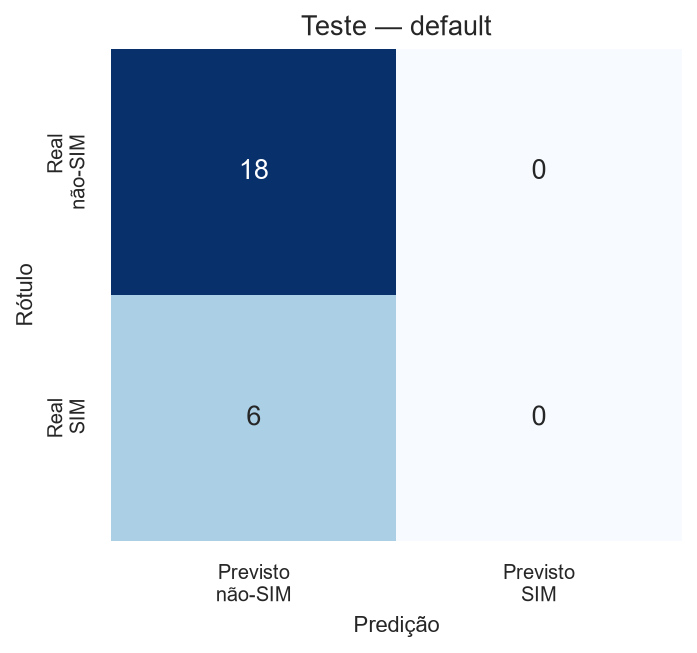

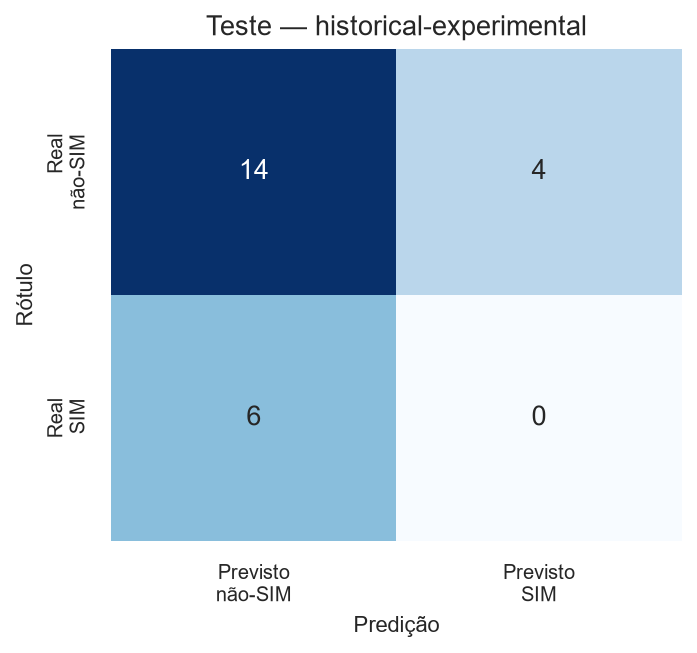

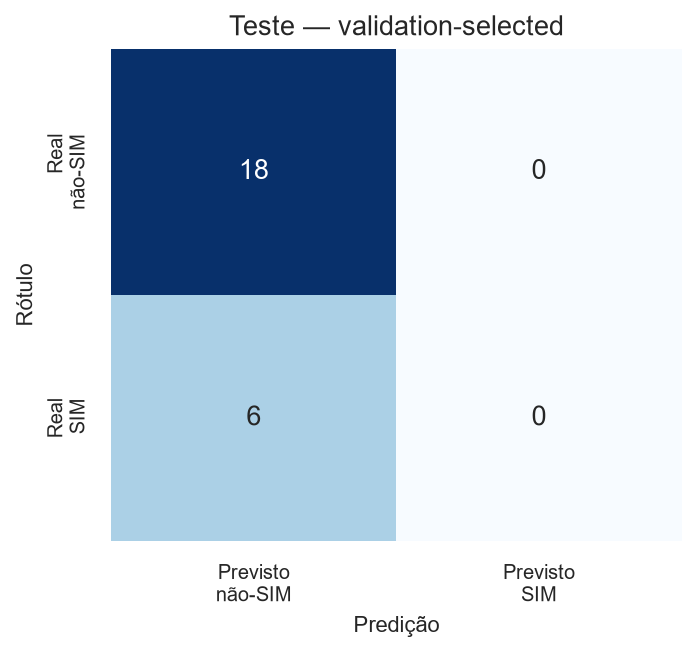

In [9]:
confusion_paths = {}
for configuration in (default, historical, tuned):
    scored, result = dtw.evaluate_configuration(
        dataset.by_split("test"), dataset.templates, configuration
    )
    confusion_paths[configuration.name] = visualization.plot_confusion_matrix(
        result,
        title=f"Teste — {configuration.name}",
        filename=f"03_matriz_confusao_teste_{configuration.name}.png",
    )
display(pd.Series(confusion_paths, name="figura").to_frame())
for path in confusion_paths.values():
    display(Image(filename=str(path)))

**Leitura.** A configuração default (0,68 / 0,5–0,5) acerta os 6 positivos na
validação, mas **nenhum** no teste, sem falsos positivos. A configuração
histórica (0,565) também não acerta nenhum positivo no teste e produz 4 falsos
positivos — exatamente o resultado registrado no relatório TypeScript
(BA = 0,3889). A configuração ajustada na validação (0,76 / 0,25–0,75 / 0,04)
mantém 6/6 na validação e cai para 0/6 no teste.

O padrão é claro: o problema não é o limiar. Se fosse, bastaria baixá-lo. A AUC
do teste é 0,324 (default) e 0,370 (ajustada), **abaixo de 0,5**: em média, os
positivos de teste são ranqueados *abaixo* dos negativos. Nenhum limiar pode
corrigir uma ordenação invertida.

## 7. Por que a margem não rejeita nada

O runtime agrupa candidatos por gloss antes de aplicar a margem. Todos os 18
templates deste projeto têm gloss `SIM`, então existe um único candidato e
`runnerUp` é indefinido. A célula confirma que nenhuma amostra é rejeitada por
margem e decompõe os motivos de rejeição.

In [10]:
def rejection_reason(row, configuration):
    if not row.motion_gate_passed:
        return "motion_gate"
    if row.best_score < configuration.threshold:
        return "below_threshold"
    if pd.notna(row.runner_up_gap) and row.runner_up_gap < configuration.min_score_margin:
        return "insufficient_margin"
    return "matched"


reason_rows = []
for configuration in (default, historical, tuned):
    for split in ("validation", "test"):
        scored, _ = dtw.evaluate_configuration(
            dataset.by_split(split), dataset.templates, configuration
        )
        reasons = scored.apply(
            lambda row: rejection_reason(row, configuration), axis=1
        ).value_counts()
        for reason, count in reasons.items():
            reason_rows.append(
                {
                    "configuração": configuration.name,
                    "split": split,
                    "motivo": reason,
                    "amostras": int(count),
                }
            )
rejection_table = pd.DataFrame(reason_rows)
rejection_table.to_csv(
    config.output_path("table", "rejection_reasons.csv"),
    index=False,
    encoding="utf-8",
)
display(rejection_table.pivot_table(index=["configuração", "split"], columns="motivo", values="amostras", fill_value=0))

motivo                              below_threshold  matched
configuração            split                               
default                 test                   24.0      0.0
                        validation             18.0      6.0
historical-experimental test                   20.0      4.0
                        validation              5.0     19.0
validation-selected     test                   24.0      0.0
                        validation             18.0      6.0

A tabela confirma: **zero** rejeições por `insufficient_margin` em todos os
cenários. O `minScoreMargin` é, na prática, um parâmetro morto para este
conjunto de um único gloss. Isso também explica por que a validação perfeita é
fácil: não há competição entre classes no nível dos templates; a decisão é
“SIM ou nada”.

## 8. Relatório de reprodução

O texto abaixo resume método, paridade e resultados e é salvo em
`outputs/reports/dtw_reproduction_report.md`.

In [11]:
report_lines = [
    "# Reprodução do DTW do Peter em Python",
    "",
    "> Gerado por `notebooks/03_reproducao_dtw.ipynb`.",
    "",
    "## Paridade",
    "",
    f"- Pares comparados contra o relatório TypeScript: **{len(parity)}**.",
    f"- Delta absoluto máximo do score combinado: **{parity['absolute_delta'].max():.3e}**.",
    f"- Configuração escolhida na validação: `threshold={selected.threshold:.2f}`, "
    f"`minMotion={selected.min_motion:.3f}`, "
    f"pesos `{selected.hand_shape_weight:.2f}/{selected.hand_trajectory_weight:.2f}`.",
    "",
    "## Resultados por configuração",
    "",
    "| Configuração | Split | TP | FN | FP | TN | Recall | Especificidade | BA | AUC |",
    "|---|---|---:|---:|---:|---:|---:|---:|---:|---:|",
]
for row in comparison_table.itertuples(index=False):
    report_lines.append(
        f"| {row.configuração} | {row.split} | {row.true_positive} | {row.false_negative} | "
        f"{row.false_positive} | {row.true_negative} | {row.recall:.3f} | "
        f"{row.specificity:.3f} | {row.balanced_accuracy:.3f} | {row.auc:.3f} |"
    )
report_lines.extend(
    [
        "",
        "## Leitura",
        "",
        "- O Python reproduz o TypeScript no limite de ponto flutuante.",
        "- A validação é perfeitamente separável; o teste não é.",
        "- A AUC de teste fica abaixo de 0,5, indicando inversão de ranking, não calibração.",
        "- A margem de score é inerte porque todos os templates compartilham o gloss SIM.",
        "",
        "## Limitações",
        "",
        "- A paridade cobre o split de teste do fixture dual; os templates legados v4 não foram avaliados.",
        "- O relatório TypeScript contém apenas métricas de teste; a validação foi reproduzida pela grade, não por um relatório independente.",
        "- Não foi possível executar o runtime TypeScript dentro deste ambiente; a comparação usa os scores já gravados no fixture.",
        "",
    ]
)
report_text = "\n".join(report_lines)
report_path = config.output_path("report", "dtw_reproduction_report.md")
report_path.write_text(report_text, encoding="utf-8")
print("Relatório:", report_path)
display(Markdown(report_text))

Relatório: C:\Users\henri\AppData\Local\Temp\opencode\peter_work\eda\outputs\reports\dtw_reproduction_report.md


# Reprodução do DTW do Peter em Python

> Gerado por `notebooks/03_reproducao_dtw.ipynb`.

## Paridade

- Pares comparados contra o relatório TypeScript: **72**.
- Delta absoluto máximo do score combinado: **2.220e-16**.
- Configuração escolhida na validação: `threshold=0.76`, `minMotion=0.040`, pesos `0.25/0.75`.

## Resultados por configuração

| Configuração | Split | TP | FN | FP | TN | Recall | Especificidade | BA | AUC |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| default | validation | 6 | 0 | 0 | 18 | 1.000 | 1.000 | 1.000 | 1.000 |
| default | test | 0 | 6 | 0 | 18 | 0.000 | 1.000 | 0.500 | 0.324 |
| historical-experimental | validation | 6 | 0 | 13 | 5 | 1.000 | 0.278 | 0.639 | 1.000 |
| historical-experimental | test | 0 | 6 | 4 | 14 | 0.000 | 0.778 | 0.389 | 0.324 |
| validation-selected | validation | 6 | 0 | 0 | 18 | 1.000 | 1.000 | 1.000 | 1.000 |
| validation-selected | test | 0 | 6 | 0 | 18 | 0.000 | 1.000 | 0.500 | 0.370 |

## Leitura

- O Python reproduz o TypeScript no limite de ponto flutuante.
- A validação é perfeitamente separável; o teste não é.
- A AUC de teste fica abaixo de 0,5, indicando inversão de ranking, não calibração.
- A margem de score é inerte porque todos os templates compartilham o gloss SIM.

## Limitações

- A paridade cobre o split de teste do fixture dual; os templates legados v4 não foram avaliados.
- O relatório TypeScript contém apenas métricas de teste; a validação foi reproduzida pela grade, não por um relatório independente.
- Não foi possível executar o runtime TypeScript dentro deste ambiente; a comparação usa os scores já gravados no fixture.


## 9. Conclusões do notebook

1. A implementação Python é numericamente equivalente ao TypeScript: delta
   máximo ~2,2 × 10⁻¹⁶ nos 72 pares de teste.
2. A busca em validação reproduz exatamente `threshold=0,76`,
   `minMotion=0,04`, pesos `0,25/0,75`.
3. Default e configuração ajustada passam 6/6 na validação; no teste, ambas
   fazem 0/6. A configuração histórica faz 0/6 com 4 falsos positivos.
4. A AUC de teste é 0,324–0,370, abaixo do acaso. O colapso é de **ranking**,
   não apenas de limiar.
5. `minScoreMargin` nunca é aplicado, pois há um único gloss.

## 10. Limitações

- A paridade é contra um relatório já produzido; não executamos o runtime
  TypeScript neste ambiente.
- O relatório de referência só cobre o teste. A validação foi reconstruída a
  partir da grade e do fixture, não de um relatório independente.
- A grade de tuning é pequena e avalia apenas três pesos de forma e nove portões;
  não explora normalizações alternativas nem arquiteturas de features.
- A calibração de probabilidade não é avaliada; a saída é um score de
  similaridade, não uma probabilidade.